# Ramen with a zero-shot anchor (CIFAR-10-C)

The anchor is the pretrained model's own prediction $p_i$, $\hat y_i$, which Ramen already computes before adapting, with zero-shot margin $m_i = p_{i,(1)} - p_{i,(2)}$. Method: `src/methods/RamenAnchor.py` (config `cfg/CIFAR10C/RamenAnchor.yaml`). Helpers: `anchor_analysis.py`.

| option | config | change |
|---|---|---|
| 1 | `lambda_self` | $\alpha_{ii} \leftarrow \alpha_{ii}(1+\lambda m_i)$; the query sits in its own queue at distance 0, so $\alpha_{ii}=e^{-H_i}$ |
| 2 | `lambda_tilt` | $\alpha_{ij} \leftarrow \alpha_{ij} e^{\lambda m_i}$ for $j$ in queue $\hat y_i$ |
| 3 | `lambda_ce` | add $\lambda m_i \nabla_w \mathrm{CE}(p_i(w), \hat y_i)$ to $\hat g_i$ (one extra backward) |
| 4 | `gate_tau`, `gate_scales` | if the adapted top class $\ne \hat y_i$ and $m_i>\tau$, retry with step $s(w_i-w)$, $s \in$ `gate_scales` |

**Plan**
1. *Diagnostic, no new runs:* bin samples by $m_i$ and count harmful (zero-shot right → Ramen wrong) and helpful flips. A margin-gated anchor can only help if harmful flips sit at high margin and helpful ones at low margin.
2. *Exact post-hoc gate:* option 4 with `gate_scales=[0]` is just “keep zero-shot when $m_i>\tau$” (the cache is written before adapting), so it can be swept without re-running.
3. *Sanity check:* `RamenAnchor` with every option off must reproduce Ramen exactly.
4. *Runs:* options 1 and 4 and their combination, plus one setting each of options 2 and 3, all on the full stream, compared with Ramen.

Under SignSGD only the relative size of the terms matters. $\sum_j \alpha_{ij}$ is $O(\text{topk})$, so $\lambda$ needs to be $O(10)$ before option 1 changes the step. The *self share of α* column in the comparison table shows how much weight the query's own gradient ends up with.

Caveat: these hyperparameters are chosen on the test stream. Confirm any winner on CIFAR-100-C (`cfg/CIFAR100C/RamenAnchor.yaml`) before trusting it.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

from ramen_analysis import CIFAR10CExperiment
import anchor_analysis as A

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = CIFAR10CExperiment(model='clip_vitbase32', tta_mode='mixed', batch_size=100, n_per_domain=None, seed=0).load()
acc = exp.evaluate(capture_probs=True)   # cached
acc

CIFAR10C: 15 corruptions x 10000 images, 10 classes, model=clip_vitbase32, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,38.66,60.84,22.18
shot_noise,42.59,63.14,20.55
impulse_noise,42.75,56.27,13.52
defocus_blur,72.61,77.12,4.51
glass_blur,43.91,64.01,20.10
motion_blur,66.68,77.55,10.87
zoom_blur,71.69,79.27,7.58
snow,73.78,80.65,6.87
frost,75.69,80.16,4.47
fog,68.85,77.93,9.08


## 1. Where do flips sit in zero-shot margin?
Blue = helpful flips, red = harmful flips. The right panel normalises by bin size, which gives the risk of adapting at that margin. `share of all harmful %` is the fraction of all harmful flips that a gate at that margin could reach.

In [3]:
A.flips_by_margin(exp)

,n,zero-shot acc %,Ramen acc %,harmful,helpful,harmful % of bin,helpful % of bin,net % of bin,share of all harmful %,share of all helpful %
zero-shot margin,,,,,,,,,,
"(-0.001, 0.1]",38247,28.09,53.98,3772,13676,9.86,35.76,25.89,44.39,53.88
"(0.1, 0.2]",19958,40.61,58.66,1996,5599,10.00,28.05,18.05,23.49,22.06
"(0.2, 0.3]",12587,51.48,64.71,1043,2708,8.29,21.51,13.23,12.27,10.67
"(0.3, 0.4]",9420,60.66,69.33,602,1419,6.39,15.06,8.67,7.08,5.59
"(0.4, 0.5]",8057,67.46,73.43,360,841,4.47,10.44,5.97,4.24,3.31
"(0.5, 0.6]",7446,73.87,77.60,212,490,2.85,6.58,3.73,2.49,1.93
"(0.6, 0.7]",7571,79.98,81.71,176,307,2.32,4.05,1.73,2.07,1.21
"(0.7, 0.8]",8790,85.97,86.63,125,183,1.42,2.08,0.66,1.47,0.72
"(0.8, 0.9]",12350,91.73,91.85,107,122,0.87,0.99,0.12,1.26,0.48


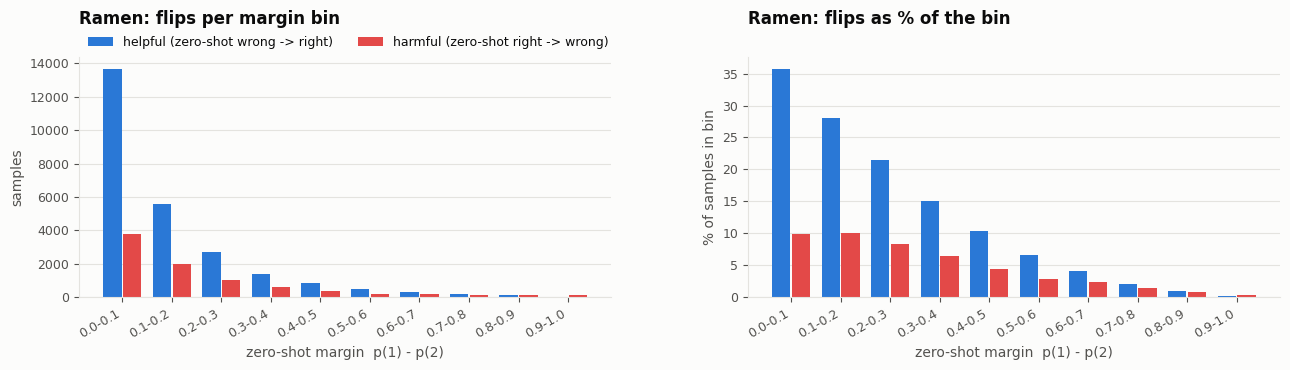

In [4]:
A.plot_flips_by_margin(exp);

## 2. Exact post-hoc gate: keep zero-shot when $m_i > \tau$
This is option 4 with `gate_scales=[0]`. `gated %` here is the share of samples with $m_i > \tau$. For a sample where Ramen already agrees with zero-shot, falling back changes nothing.

In [5]:
gate = A.margin_gate_sweep(exp)
print(f"Ramen: {gate.attrs['Ramen acc %']:.2f}%")
gate

Ramen: 72.61%


,gated %,acc %,harmful,helpful
tau,,,,
0.1,74.50,67.96,3772,13676
0.2,61.20,70.36,5768,19275
0.3,52.81,71.47,6811,21983
0.4,46.53,72.01,7413,23402
0.5,41.15,72.34,7773,24243
0.6,36.19,72.52,7985,24733
0.7,31.14,72.61,8161,25040
0.8,25.28,72.65,8286,25223


## 3. Sanity check: every option off reproduces Ramen

In [6]:
exp.run('RamenAnchor', name='anchor_off', cfg={})
same = (exp.results['anchor_off'].pred.values == exp.results['Ramen'].pred.values).mean()
print(f'prediction agreement with Ramen: {same:.4%}')

anchor_off: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_anchor_off.pkl
prediction agreement with Ramen: 100.0000%


## 4. Variants
Each run takes a few minutes on the full stream. Results are cached under their name in `results/`, so re-running this cell is instant.

In [7]:
VARIANTS = {
    'self10':          {'lambda_self': 10},
    'self50':          {'lambda_self': 50},
    'gate0.3':         {'gate_tau': 0.3},
    'gate0.5':         {'gate_tau': 0.5},
    'self10+gate0.5':  {'lambda_self': 10, 'gate_tau': 0.5},
    'tilt1':           {'lambda_tilt': 1.0},
    'ce0.5':           {'lambda_ce': 0.5},
}
for name, cfg in VARIANTS.items():
    exp.run('RamenAnchor', name=name, cfg=cfg)
NAMES = ['Ramen'] + list(VARIANTS)

self10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_self10.pkl
self50: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_self50.pkl
gate0.3: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_gate0.3.pkl
gate0.5: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_gate0.5.pkl
self10+gate0.5: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_self10+gate0.5.pkl
tilt1: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_tilt1.pkl
ce0.5: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_

`step shrunk %` is the share of samples whose step option 4 shrank. `self share of alpha %` is $\alpha_{ii}/\sum_j\alpha_{ij}$ after the anchor, averaged over samples.

In [8]:
A.compare_variants(exp, ['anchor_off'] + NAMES)

,avg acc %,worst corruption acc %,delta vs Ramen,corruptions worse than Ramen,harmful,helpful,harmful @ m>0.3,helpful @ m>0.3,self share of alpha %,step shrunk %
anchor_off,72.61,56.27,0.00,0.0,8498.0,25381.0,1687.0,3398.0,2.70,0.00
Ramen,72.61,56.27,0.00,0.0,8498.0,25381.0,1687.0,3398.0,NaN,NaN
self10,72.13,55.98,-0.48,11.0,6400.0,22567.0,400.0,1406.0,14.59,0.00
self50,71.19,55.58,-1.42,13.0,5012.0,19769.0,269.0,517.0,33.42,0.00
gate0.3,71.48,55.56,-1.14,15.0,6805.0,21985.0,6.0,21.0,2.70,4.10
gate0.5,72.34,56.13,-0.28,12.0,7773.0,24243.0,962.0,2260.0,2.70,1.45
self10+gate0.5,72.08,55.96,-0.53,11.0,6283.0,22368.0,283.0,1207.0,14.59,0.23
tilt1,72.59,56.03,-0.02,8.0,6981.0,23829.0,731.0,2281.0,3.97,0.00
ce0.5,70.66,55.39,-1.95,15.0,3977.0,17928.0,280.0,868.0,2.70,0.00


In [9]:
A.domain_table(exp, ['NoAdapt'] + NAMES)

,NoAdapt,Ramen,self10,self50,gate0.3,gate0.5,self10+gate0.5,tilt1,ce0.5
gaussian_noise,38.66,60.84,60.10,58.88,57.91,59.65,59.62,60.71,58.45
shot_noise,42.59,63.14,61.92,60.58,60.06,61.99,61.49,62.92,60.52
impulse_noise,42.75,56.27,55.98,55.58,55.56,56.13,55.96,56.03,55.39
defocus_blur,72.61,77.12,77.63,77.17,77.05,77.34,77.68,77.77,77.03
glass_blur,43.91,64.01,62.69,60.44,62.25,63.61,62.61,63.69,58.78
motion_blur,66.68,77.55,75.85,74.31,75.47,76.89,75.78,76.68,73.54
zoom_blur,71.69,79.27,78.35,77.58,78.17,79.00,78.45,79.13,77.11
snow,73.78,80.65,80.38,79.86,79.91,80.36,80.40,80.79,79.18
frost,75.69,80.16,80.34,80.24,79.99,80.35,80.39,80.63,79.83
fog,68.85,77.93,78.38,77.72,77.44,78.00,78.30,78.38,77.48


Harmful and helpful flip rate per margin bin for each method. A working anchor lowers the red-panel curve at high margin without lowering the helpful curve at low margin.

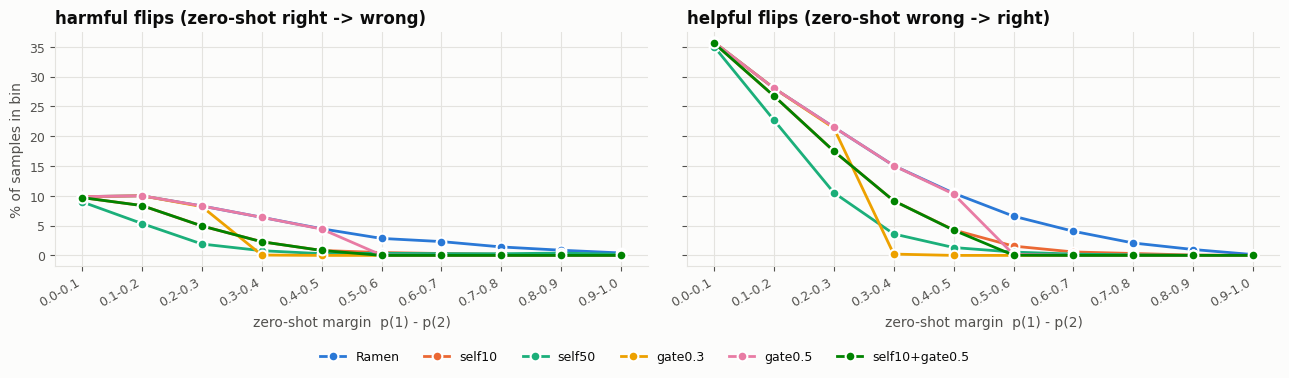

In [10]:
A.plot_variant_flips_by_margin(exp, ['Ramen', 'self10', 'self50', 'gate0.3', 'gate0.5', 'self10+gate0.5']);

## 5. The cat → dog image from the confusion notebook (fog #2231)

In [11]:
A.sample_predictions(exp, NAMES, exp.environments.index('fog'), 2231)

fog #2231: true cat, zero-shot margin 0.308


,pred,correct,conf
zero-shot,cat,True,NaN
Ramen,dog,False,0.987204
self10,cat,True,0.791569
self50,cat,True,0.993108
gate0.3,cat,True,0.561462
gate0.5,dog,False,0.987204
self10+gate0.5,cat,True,0.791569
tilt1,dog,False,0.964837
ce0.5,cat,True,0.987534
